# Jensen Huang reinstated as NVIDIA CEO: who clicked first?

**Event:** NVIDIA's GlobeNewswire release, published **8:55:41 AM ET, 2026-11-23** (the page displays it as "08:55 ET"; the exact second is in its metadata, section 0).
**Question:** when did takers start buying YES on "Jensen returns", which venue moved first, and was Hyperliquid's NVDA perp the trigger?

The written finding is [`reports/jensen.md`](../reports/jensen.md); this notebook is the evidence behind it. Event window, markets and thresholds live in [`events/jensen.toml`](../events/jensen.toml); the raw pulls and their provenance are in `data/raw/jensen/` (see `manifest.json`). Times are ET (UTC−5).

| Venue | What's public | Timestamp | Taker identity |
|---|---|---|---|
| Hyperliquid `xyz:NVDA` | every fill (Ironflow; S3 archive) | block time, ms | wallet |
| Kalshi | full trade tape (older trades via `/historical/trades`) | matching engine, µs | none |
| Polymarket (polymarket.com) | every taker fill (on-chain) | Polygon block, 1 s, ~1–3 s after the match | proxy wallet |
| Pascal (pascal.trade) | every trade, explicit taker side | matching engine, ms | maker and taker wallets |

Polymarket US is left out: it publishes no trade tape, only about one display price a minute.

In [1]:
%matplotlib inline
import pandas as pd
from newsflow import analysis, pipeline
from newsflow.event import load

pd.set_option("display.max_rows", 200, "display.width", 200, "display.float_format", "{:,.4g}".format)
ev = load(pipeline.ROOT / "events" / "jensen.toml")
tape = pipeline.tape(ev)
buys = tape[tape.side > 0]
tape.groupby(["venue", "label"]).agg(fills=("qty", "size"), first=("clock", "min"), last=("clock", "max")).join(
    buys.groupby(["venue", "label"]).agg(yes_buy_qty=("qty", "sum"), yes_buy_usd=("usd", "sum")))

fills         first          last  yes_buy_qty  yes_buy_usd
venue       label                                                                                     
hyperliquid HL xyz:NVDA                    11535  08:54:00.023  08:57:59.966    4.851e+05    7.113e+07
kalshi      K CEO hire = Jensen returns       23  08:55:57.906  08:57:59.393    1.084e+04        1,856
            K next CEO = Jensen             1228  08:54:12.566  08:57:58.451    2.072e+06    8.557e+05
            K next employer = Nvidia         318  08:55:47.179  08:57:55.774     1.18e+05    3.147e+04
pascal      Pascal next CEO = Jensen           4  08:56:11.494  08:57:46.046          300          205
polymarket  PM rejoin by december-31-2026    134  08:54:50.000  08:57:59.000    2.291e+05    1.163e+05
            PM rejoin by december-31-2027    111  08:55:53.000  08:57:44.000    5.563e+04     3.11e+04
            PM rejoin by march-31-2027        63  08:55:53.000  08:57:23.000    1.457e+04        7,460
            PM rejoin by november-30-2026    185  08:54:14.000  08:57:53.000    2.268e+05    1.271e+05

## 0. When did the release actually go out?
GlobeNewswire's page displays "November 23, 2026 08:55 ET", but its own metadata (`og:article:published_time`, JSON-LD `datePublished`) carries the second: **13:55:41Z = 8:55:41 ET**. Calibration from NVIDIA's other GlobeNewswire releases: scheduled ones land exactly on :00 (earnings 16:20:00, events 17:00:00, product news 11:00:00); unscheduled ones carry real seconds (CEO transition 08:48:12, board statement 14:07:46, this one 08:55:41). So 8:55:41 is when GlobeNewswire actually pushed it, not a scheduled slot.

Other sources, all later. X post times are decoded from post ids, which embed the creation time in ms. The GlobeNewswire pages were captured with a real browser, because GlobeNewswire returns 403 to scripted clients; the evidence is in `data/raw/jensen/release-timing.json.gz`.

In [2]:
from newsflow import rawstore, timing
rt = pd.DataFrame(timing.release_table(rawstore.read(pipeline.raw_dir(ev), "release-timing")))
pub = ev.marks["GlobeNewswire published"]
rt["ET"] = pd.to_datetime(rt.t_ms, unit="ms", utc=True).dt.tz_convert(ev.tz).dt.strftime("%m-%d %H:%M:%S.%f").str[:-3]
rt["vs_release_s"] = ((rt.t_ms - pub) / 1000).where(rt.t_ms >= pub - 86_400_000)
rt[["ET", "source", "precision", "vs_release_s"]]

,ET,source,precision,vs_release_s
0,11-10 14:07:46.000,GlobeNewswire: statement-from-the-independent-...,1 s,NaN
1,11-12 08:48:12.000,GlobeNewswire: nvidia-announces-ceo-transition,1 s,NaN
2,11-16 11:00:00.000,GlobeNewswire: nvidia-announces-collaboration-...,1 s,NaN
3,11-16 11:00:00.000,GlobeNewswire: nvidia-expands-vera-cpu-platfor...,1 s,NaN
4,11-16 11:00:00.000,GlobeNewswire: nvidia-introduces-nemotron-for-...,1 s,NaN
5,11-17 05:00:00.000,GlobeNewswire: nvidia-board-of-directors-estab...,1 s,NaN
6,11-17 16:20:00.000,GlobeNewswire: nvidia-announces-financial-resu...,1 s,NaN
7,11-17 17:18:15.000,GlobeNewswire: nvidia-expands-commitments-with...,1 s,NaN
8,11-19 17:00:00.000,GlobeNewswire: nvidia-announces-upcoming-event...,1 s,NaN
9,11-23 08:55:41.000,GlobeNewswire: nvidia-board-reinstates-jensen-...,1 s,0


| ET | What | After the release |
|---|---|---|
| 8:55:41 | GlobeNewswire publishes | 0 |
| 8:55:41.362 | HL `xyz:NVDA` sweep by `0x25773676…` | same second (≤0.4 s if published at :41.0) |
| 8:55:48.399 | Kalshi first burst (280K YES) | +7.4 s |
| 8:55:50 | Polymarket first fill, $34 on Nov 30 (block time) | +9 s |
| 8:55:51.5 | First X posts (PM Pulse; post not identified) | +10.5 s |
| 8:55:53 | Polymarket first burst (block time) | +12 s |
| 8:56:11.494 | Pascal first trade, $100 | +30.5 s |
| 8:56:16.1 | @DeItaone | +35 s |
| 8:57:54 | EDGAR 8-K accepted | +2 m 13 s |
| 8:58:03.1 | @nvidianewsroom | +2 m 22 s |

The 41 s "gap" between the displayed 8:55 stamp and the first trades is the gap between the minute label and the real publish second. Against the real second, HL reacted within the same second. GlobeNewswire publishes only to the second, so it can't tell whether the HL sweep came a few hundred ms before or after.

## 1. First taker bursts per market
A *burst* is a bucket where YES/long taker buying reaches a venue-specific size (`[bursts]` in the event config): HL $100k per 0.5 s, Kalshi $5k per 0.5 s, Polymarket $2k per 1 s (block time is whole seconds, and the nearest-dated Polymarket markets were 3–12¢).

In [3]:
b = analysis.bursts_by_market(tape, ev.bursts)
for label, t in b.groupby("label", sort=False):
    print(f"\n== {label}")
    print(t.head(8)[["clock", "qty", "usd", "px_lo", "px_hi", "top_taker", "top_share"]].to_string(index=False))


== HL xyz:NVDA
       clock   qty       usd  px_lo  px_hi  top_taker  top_share
08:55:41.068 1,759 2.392e+05  135.9    136 0x25773676     0.9985
08:55:41.622 4,582 6.235e+05    136  136.1 0x0de52cf0     0.5612
08:55:42.022 3,186 4.336e+05  136.1  136.1 0x5234a0bb     0.6278
08:55:42.509 2,993 4.074e+05  136.1  136.2 0x0de52cf0     0.6573
08:55:43.027 3,272 4.456e+05  136.1  136.3 0x0de52cf0     0.5811
08:55:43.519 1,638 2.236e+05  136.3  136.6 0x0de52cf0     0.5517
08:55:44.047 1,354 1.851e+05  136.5  136.8 0x0de52cf0     0.6403
08:55:44.514 4,227 5.788e+05  136.8  137.2 0x21ba61c0     0.4631

== K next CEO = Jensen
       clock       qty       usd  px_lo  px_hi   top_taker  top_share
08:55:48.399 2.802e+05 4.809e+04   0.17   0.18 (anonymous)          1
08:55:57.906 9.105e+04 1.637e+04   0.17   0.18 (anonymous)          1
08:56:03.200   2.5e+05  4.78e+04   0.18   0.21 (anonymous)          1
08:56:05.510 3.994e+05 1.008e+05    0.2   0.33 (anonymous)          1
08:56:11.039 9.337e+04 3.

## 2. Timeline
Each market's first burst, with lags (seconds) against the first Hyperliquid burst and the reference timestamps.

In [4]:
first = analysis.first_bursts(b, ev.marks)
hl0 = first.query("venue == 'hyperliquid'").t_ms.min()
first.drop(columns=["t_ms", "top_share"])

,clock,qty,usd,px_lo,px_hi,top_taker,venue,label,vs_first_HL_s,vs_GlobeNewswire published_s,vs_First X posts_s
0,08:55:41.068,"1,759",2.392e+05,135.9,136,0x25773676,hyperliquid,HL xyz:NVDA,0,0.068,-10.43
1,08:55:48.399,2.802e+05,4.809e+04,0.17,0.18,(anonymous),kalshi,K next CEO = Jensen,7.331,7.399,-3.101
2,08:55:53.000,5.098e+04,"6,329",0.1241,0.1241,0x3e03eaee,polymarket,PM rejoin by december-31-2026,11.93,12,1.5
3,08:55:57.902,7.108e+04,"8,717",0.1,0.15,(anonymous),kalshi,K next employer = Nvidia,16.83,16.9,6.402
4,08:56:04.000,"6,153","2,457",0.398,0.42,0x853c37a9,polymarket,PM rejoin by december-31-2027,22.93,23,12.5
5,08:56:11.494,169,100.2,0.593,0.593,EWGv5fY5VR,pascal,Pascal next CEO = Jensen,30.43,30.49,19.99
6,08:56:14.000,2.924e+04,1.461e+04,0.4996,0.4996,0x3e03eaee,polymarket,PM rejoin by november-30-2026,32.93,33,22.5
7,08:56:43.000,"2,608","2,304",0.8835,0.8835,0x73e35ce0,polymarket,PM rejoin by march-31-2027,61.93,62,51.5


- Hyperliquid moved first.
- HL's first burst landed in the same second GlobeNewswire published (8:55:41).
- Kalshi's first burst (the 280k-contract print in the PM Pulse chart) came 7.3 s after HL, 7.4 s after the release, while HL NVDA was already up.
- Pascal barely traded the news: its first trade after the release was 169 YES at 59.3¢ ($100) at 8:56:11.494 (+30.5 s), one of 4 trades in the whole window.
- Polymarket's block times run ~1–3 s behind the match, so its true first burst is a little earlier than shown; it is still after Kalshi's. One $34 fill (1,030 YES at 3.3¢ on Nov 30) came earlier, at 8:55:50 block time.
- Kalshi printed two small YES fills at 8:55:43.9–44.0 ($262 at 17¢), before its first burst. That market had 9 fills in the 101 s before the release, so they can't be told apart from background trading.

## 3. Kalshi vs Polymarket
YES taker dollars per second, 8:55:40–8:56:40, then what each market's early takers paid and made. Every market here resolved YES at $1.

In [5]:
W0 = hl0 - 1_000
w = buys[buys.venue.isin(["kalshi", "polymarket"]) & buys.t_ms.between(W0, W0 + 60_000)].copy()
w["group"] = w.label.where(w.venue == "kalshi", "PM rejoin (all markets)")
w["sec"] = w.time.dt.floor("s").dt.strftime("%H:%M:%S")
per_sec = w.pivot_table(index="sec", columns="group", values="usd", aggfunc="sum").fillna(0).round(0)
per_sec[per_sec.sum(axis=1) >= 1000]

group,K CEO hire = Jensen returns,K next CEO = Jensen,K next employer = Nvidia,PM rejoin (all markets)
sec,,,,
08:55:48,0,4.809e+04,0,0
08:55:53,0,14,165,"6,395"
08:55:54,0,"1,832",0,0
08:55:55,0,0,5,"5,430"
08:55:56,0,0,1,"7,002"
08:55:57,"1,757",1.637e+04,"8,717",0
08:55:58,0,"1,309",93,57
08:56:01,0,0,0,"4,531"
08:56:03,0,4.78e+04,0,0


In [6]:
pm_k = first[first.venue != "hyperliquid"]
pd.DataFrame({(r.label, f"first {s}s"): analysis.edge(buys[buys.label == r.label], r.t_ms, s)
              for r in pm_k.itertuples() for s in (15, 30, 60)}).T

risked_usd  contracts   vwap  profit_at_1_usd  fills
K next CEO = Jensen           first 15s   1.154e+05  6.394e+05 0.1805         5.24e+05    108
                              first 30s   5.779e+05  1.696e+06 0.3408        1.118e+06    604
                              first 60s   6.743e+05  1.833e+06 0.3678        1.159e+06    812
PM rejoin by december-31-2026 first 15s   2.062e+04  1.258e+05 0.1639        1.052e+05     23
                              first 30s   2.199e+04  1.286e+05 0.1709        1.066e+05     32
                              first 60s   2.617e+04  1.354e+05 0.1933        1.093e+05     65
K next employer = Nvidia      first 15s       9,234  7.373e+04 0.1253        6.449e+04     56
                              first 30s   1.186e+04  8.233e+04  0.144        7.047e+04    100
                              first 60s   1.971e+04  9.922e+04 0.1986        7.951e+04    180
PM rejoin by december-31-2027 first 15s   1.874e+04  3.987e+04 0.4701        2.113e+04     12
                              first 30s   1.951e+04  4.097e+04  0.476        2.147e+04     19
                              first 60s   2.494e+04  4.726e+04 0.5278        2.232e+04     52
Pascal next CEO = Jensen      first 15s       100.2        169  0.593            68.78      1
                              first 30s       100.2        169  0.593            68.78      1
                              first 60s       100.2        169  0.593            68.78      1
PM rejoin by november-30-2026 first 15s   2.592e+04  5.186e+04 0.4998        2.594e+04     14
                              first 30s   2.914e+04  5.713e+04 0.5101        2.799e+04     27
                              first 60s   1.025e+05  1.336e+05 0.7671        3.112e+04     45
PM rejoin by march-31-2027    first 15s       2,314      2,619 0.8836            304.8      2
                              first 30s       2,643      2,969 0.8902            325.9      4
                              first 60s       4,009      4,401 0.9108            392.4      7

Kalshi printed far more size in the first 30 s than any Polymarket market. Kalshi's next-CEO market started at 17¢; Polymarket's nearest-dated markets started cheaper (Nov-30 about 3¢, Dec-31-2026 about 12¢), but their books were thin: Nov-30 went from about 3¢ to 50¢ in roughly 20 s, so only the first few wallets got the cheap prices.

## 4. The fastest Polymarket wallets
Takers are on-chain, so they are identifiable. Kalshi takers are anonymous; its closest equivalent is the burst table in section 1.

In [7]:
pm0 = first.query("venue == 'polymarket'").t_ms.min()
wallets = analysis.early_takers(buys[buys.venue == "polymarket"], pm0, 60)
wallets.index = wallets.index.str[:12]
wallets.markets = wallets.markets.str.replace("PM rejoin by ", "")
wallets.head(15)

,first_fill,markets,contracts,risked_usd,avg_px,profit_at_1_usd
taker,,,,,,
0x122cb94c43,08:55:53.000,"december-31-2026, december-31-2027, march-31-2...","5,995","2,495",0.4162,"3,500"
0x3e03eaee9f,08:55:53.000,"december-31-2026, november-30-2026",9.921e+04,2.216e+04,0.2233,7.706e+04
0x853c37a959,08:55:55.000,"december-31-2026, december-31-2027, november-3...",1.048e+05,1.327e+04,0.1266,9.156e+04
0x167a807987,08:55:55.000,november-30-2026,208.6,10.22,0.049,198.3
0xfe41328c99,08:55:55.000,december-31-2026,22,2.508,0.114,19.49
0x5203dcfc24,08:55:55.000,"december-31-2026, december-31-2027","1,894",605.8,0.3198,"1,289"
0x4e12f04a8e,08:55:56.000,"december-31-2026, november-30-2026",293.6,37.26,0.1269,256.4
0x6288e13f5e,08:55:58.000,"december-31-2026, november-30-2026",229.1,56.11,0.2449,173
0xf727b38efd,08:56:01.000,november-30-2026,38.14,5.68,0.1489,32.46


## 5. Is the Hyperliquid data right?
The HL fills come through Ironflow, a third-party indexer, because Hyperliquid's API serves no market-wide trade history. Two checks against Hyperliquid's own API, both saved as raw files at fetch time (`hl-candles-*`, `hl-userfills-*`):

1. **Every trade:** per-minute trade count, base volume and OHLC rebuilt from Ironflow vs Hyperliquid's 1-minute candles.
2. **Fill by fill:** for 40 wallets active in the window, every fill Hyperliquid returns from `userFillsByTime` must exist in Ironflow with the same price, size, time, order id and side. HL's fills also carry `crossed` (whether that side took liquidity), which scores our taker inference. Ironflow has no such flag, so we take the leg with the newer order id as the taker.

In [8]:
checks = pipeline.hl_checks(ev)["xyz:NVDA"]
checks["candles"]

,minute,hl_trades,ironflow_trades,hl_volume,ironflow_volume,hl_ohlc,ironflow_ohlc,match
0,08:54,161,161,"1,357","1,357",136.0/136.05/135.91/136.02,136/136.05/135.91/136.02,True
1,08:55,2006,2006,1.485e+05,1.485e+05,136.02/143.66/135.91/143.66,136.02/143.66/135.91/143.66,True
2,08:56,5654,5654,2.779e+05,2.779e+05,143.66/153.27/139.57/151.77,143.66/153.27/139.57/151.77,True
3,08:57,3714,3714,1.509e+05,1.509e+05,152.8/158.88/151.21/154.78,152.8/158.88/151.21/154.78,True


In [9]:
f = checks["fills"]
print(f"{f['wallets']} wallets, {f['fills']:,} HL fills: {f['in_ironflow']:,} found in Ironflow, {f['identical']:,} identical, "
      f"taker inference agrees with HL's crossed flag on {f['taker_ok']:,} ({f['taker_ok'] / f['fills']:.1%})")
r = f["rows"].assign(minute=lambda d: pd.to_datetime(d.time_ms, unit="ms", utc=True).dt.tz_convert(ev.tz).dt.strftime("%H:%M"))
early = r[r.time_ms.between(hl0 - 1_000, hl0 + 11_000)]
print(f"first-burst window, {len(early)} fills: {early.taker_ok.mean():.1%} agree")
r.groupby("minute").taker_ok.agg(fills="size", agree="mean")

40 wallets, 7,495 HL fills: 7,495 found in Ironflow, 7,495 identical, taker inference agrees with HL's crossed flag on 7,076 (94.4%)
first-burst window, 625 fills: 100.0% agree


,fills,agree
minute,,
08:54,14,1
08:55,1157,0.9844
08:56,4265,0.9081
08:57,2059,0.9956


- **The fills are Hyperliquid's.** All 11,535 trades in the window match HL's candles exactly (count, volume, OHLC), and every one of the 7,495 per-wallet fills HL served is in Ironflow, field for field.
- **The taker side is inferred, and right 94.4% of the time.** Errors cluster in 8:56 (91% agreement), when price was pinned at 143.66. Most likely these are trigger orders (stops): placed earlier, so they carry older order ids, then crossed *(inference)*. Around the first burst (8:55:40–8:55:52) agreement is 100%, so the lead-time finding doesn't depend on the inference. The first move shows without any side inference anyway: price walks the ask from 135.93 at 8:55:41.362.
- **Where it matters:** per-bar long/short splits after 8:56 carry a few percent of misattributed flow. Hyperliquid's own S3 archive (`hyperliquid.source = "s3"`) has `crossed` on every fill and removes the inference; it needs AWS credentials.

## 6. Hyperliquid: the lead signal

In [10]:
h = tape[tape.venue == "hyperliquid"]
lead = h[(h.side > 0) & h.t_ms.between(hl0 - 1000, hl0 + 10_000)]
print("first 10 s of long-taker flow, by wallet:")
print(lead.groupby("taker").agg(first=("clock", "min"), usd=("usd", "sum"), px_lo=("price", "min"), px_hi=("price", "max"))
          .sort_values("usd", ascending=False).head(8).rename(index=lambda a: a[:12]).to_string())

pre = h[h.t_ms < hl0].price.iloc[-1]
print()
for s in (0, 5, 10, 13, 30, 60):
    p = h[h.t_ms <= hl0 + s * 1000].price.iloc[-1]
    print(f"+{s:>2}s  {p:8.2f}  ({p / pre - 1:+.1%})")
cap = h[h.t_ms.between(hl0 + 13_000, hl0 + 28_000)]
print(f"\n{cap.clock.iloc[0]}-{cap.clock.iloc[-1]}: {len(cap)} trades, max {cap.price.max()}, {(cap.price == cap.price.max()).mean():.0%} printed at the max")

first 10 s of long-taker flow, by wallet:
                     first       usd  px_lo  px_hi
taker                                             
0x2577367690  08:55:41.362 2.961e+06  135.9  140.8
0x0de52cf07a  08:55:41.622 2.361e+06    136  141.7
0x25ad068ba9  08:55:43.648 1.656e+06  136.4    142
0x177019594b  08:55:42.022 8.803e+05  136.1    139
0xfe7ce058ed  08:55:42.908 7.779e+05  136.1    140
0x7c0a4bd875  08:55:43.860 5.572e+05  136.5  140.3
0xfc667adba8  08:55:41.952 5.521e+05  136.1  139.3
0x8b053f3736  08:55:43.110 3.548e+05  136.2  138.8

+ 0s    135.92  (-0.0%)
+ 5s    138.08  (+1.6%)
+10s    141.99  (+4.5%)
+13s    143.66  (+5.7%)
+30s    144.31  (+6.2%)
+60s    149.75  (+10.2%)

08:55:54.101-08:56:08.951: 1323 trades, max 143.66, 50% printed at the max


- One wallet (`0x25773676…`) swept the `xyz:NVDA` ask first. An earlier pull showed the same wallet hitting `io:NVDA` at 8:55:46; those raw records weren't kept, so `io:NVDA` is out of this dataset until it is recovered from Hyperliquid's S3 archive.
- For about 15 s after +13 s nothing printed above 143.66 (+5.7%) despite heavy buying, which looks like a HIP-3 price-band cap *(inference: not checked against the deployer's parameters)*. HL's price understated the move exactly while the first Kalshi and Polymarket bursts were landing.

## 7. Everything on one clock
Each panel labels its first burst and its largest ones: size, price range, cash risked and payout at $1 (binaries), or long notional and the top wallet's share (HL). Panel titles carry the window totals.

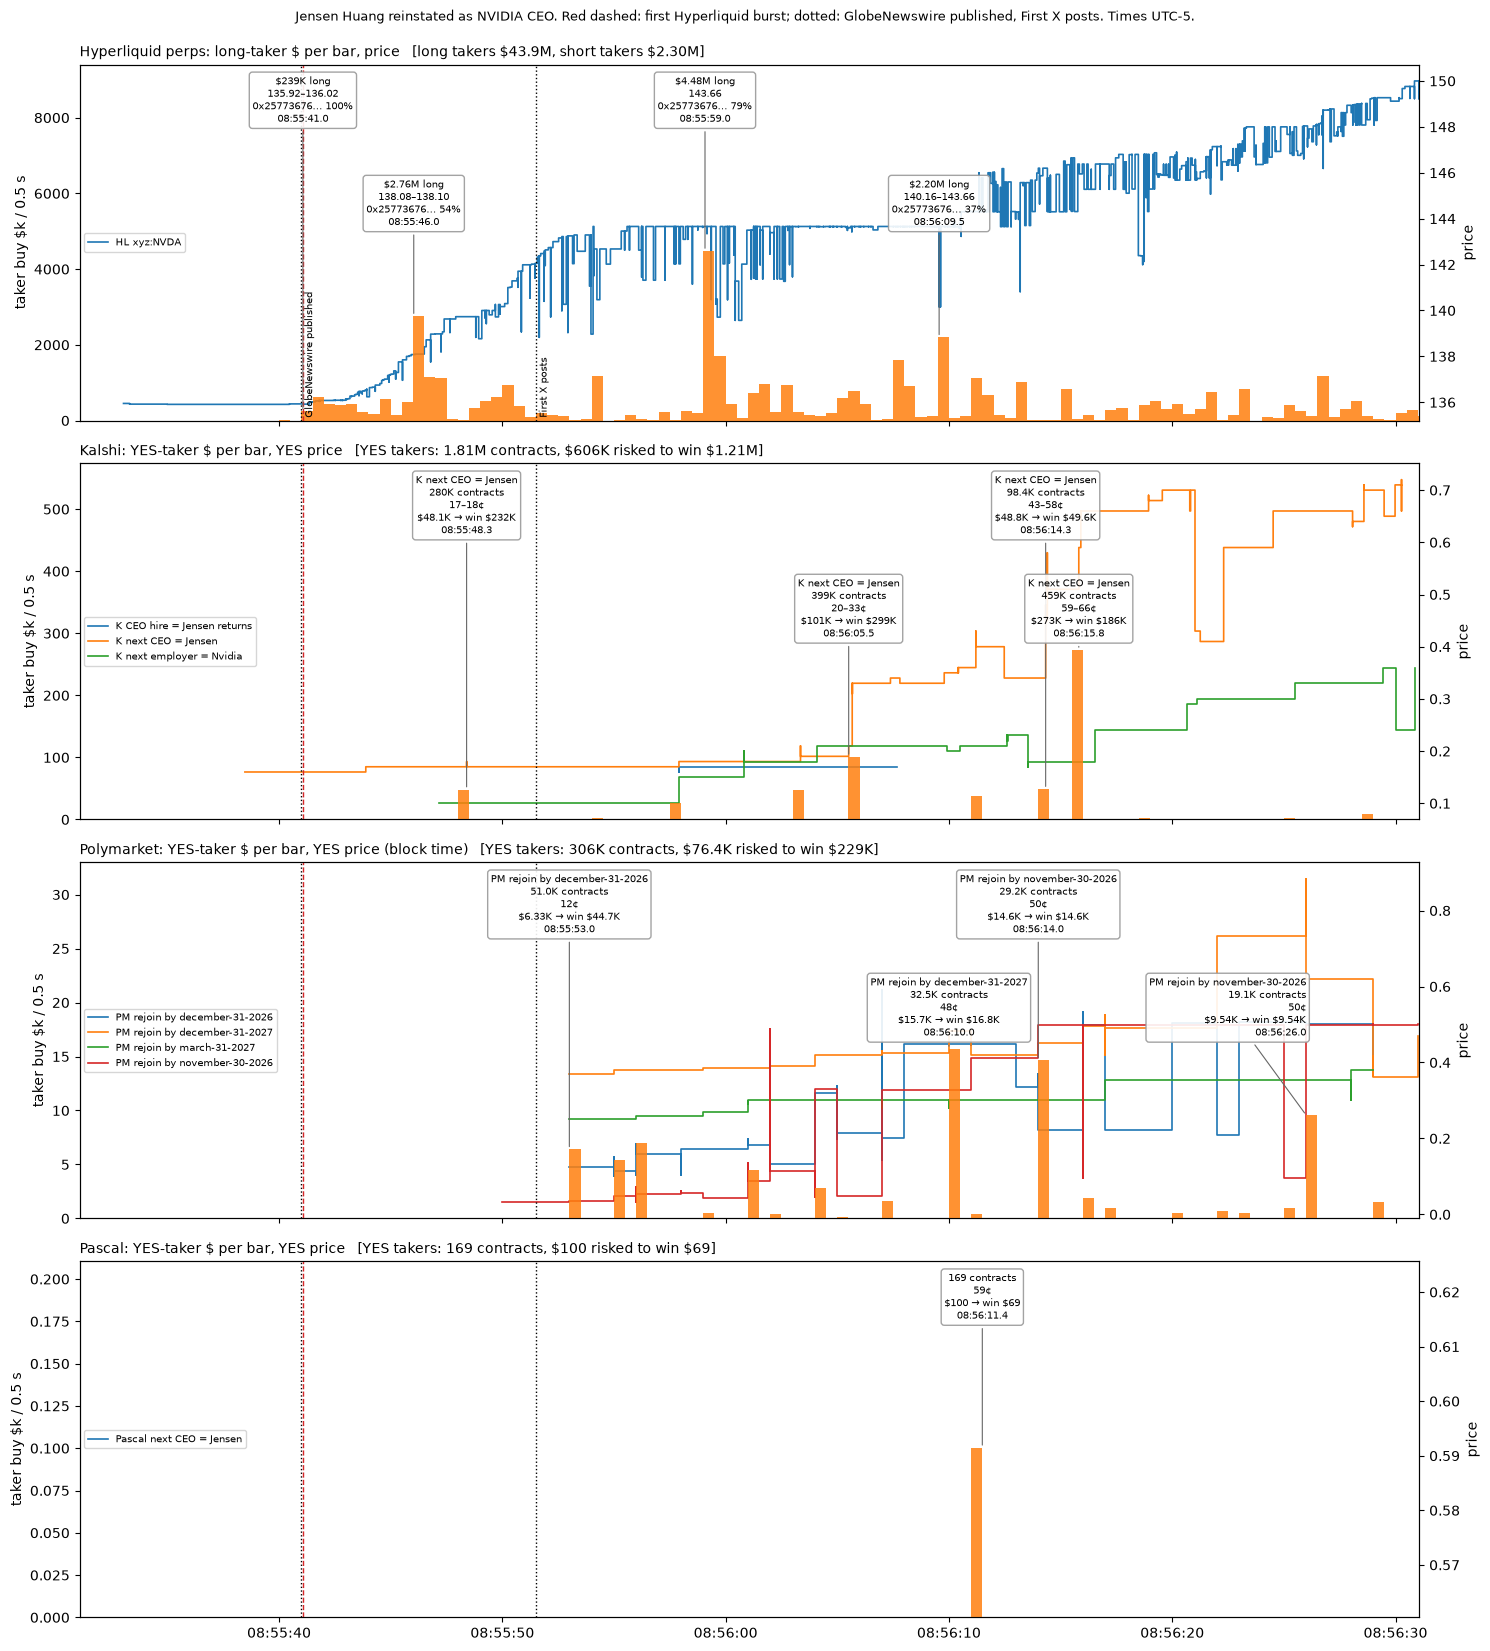

In [11]:
analysis.chart(tape, ev, hl0 - 10_000, hl0 + 50_000, 500, annotate=4);

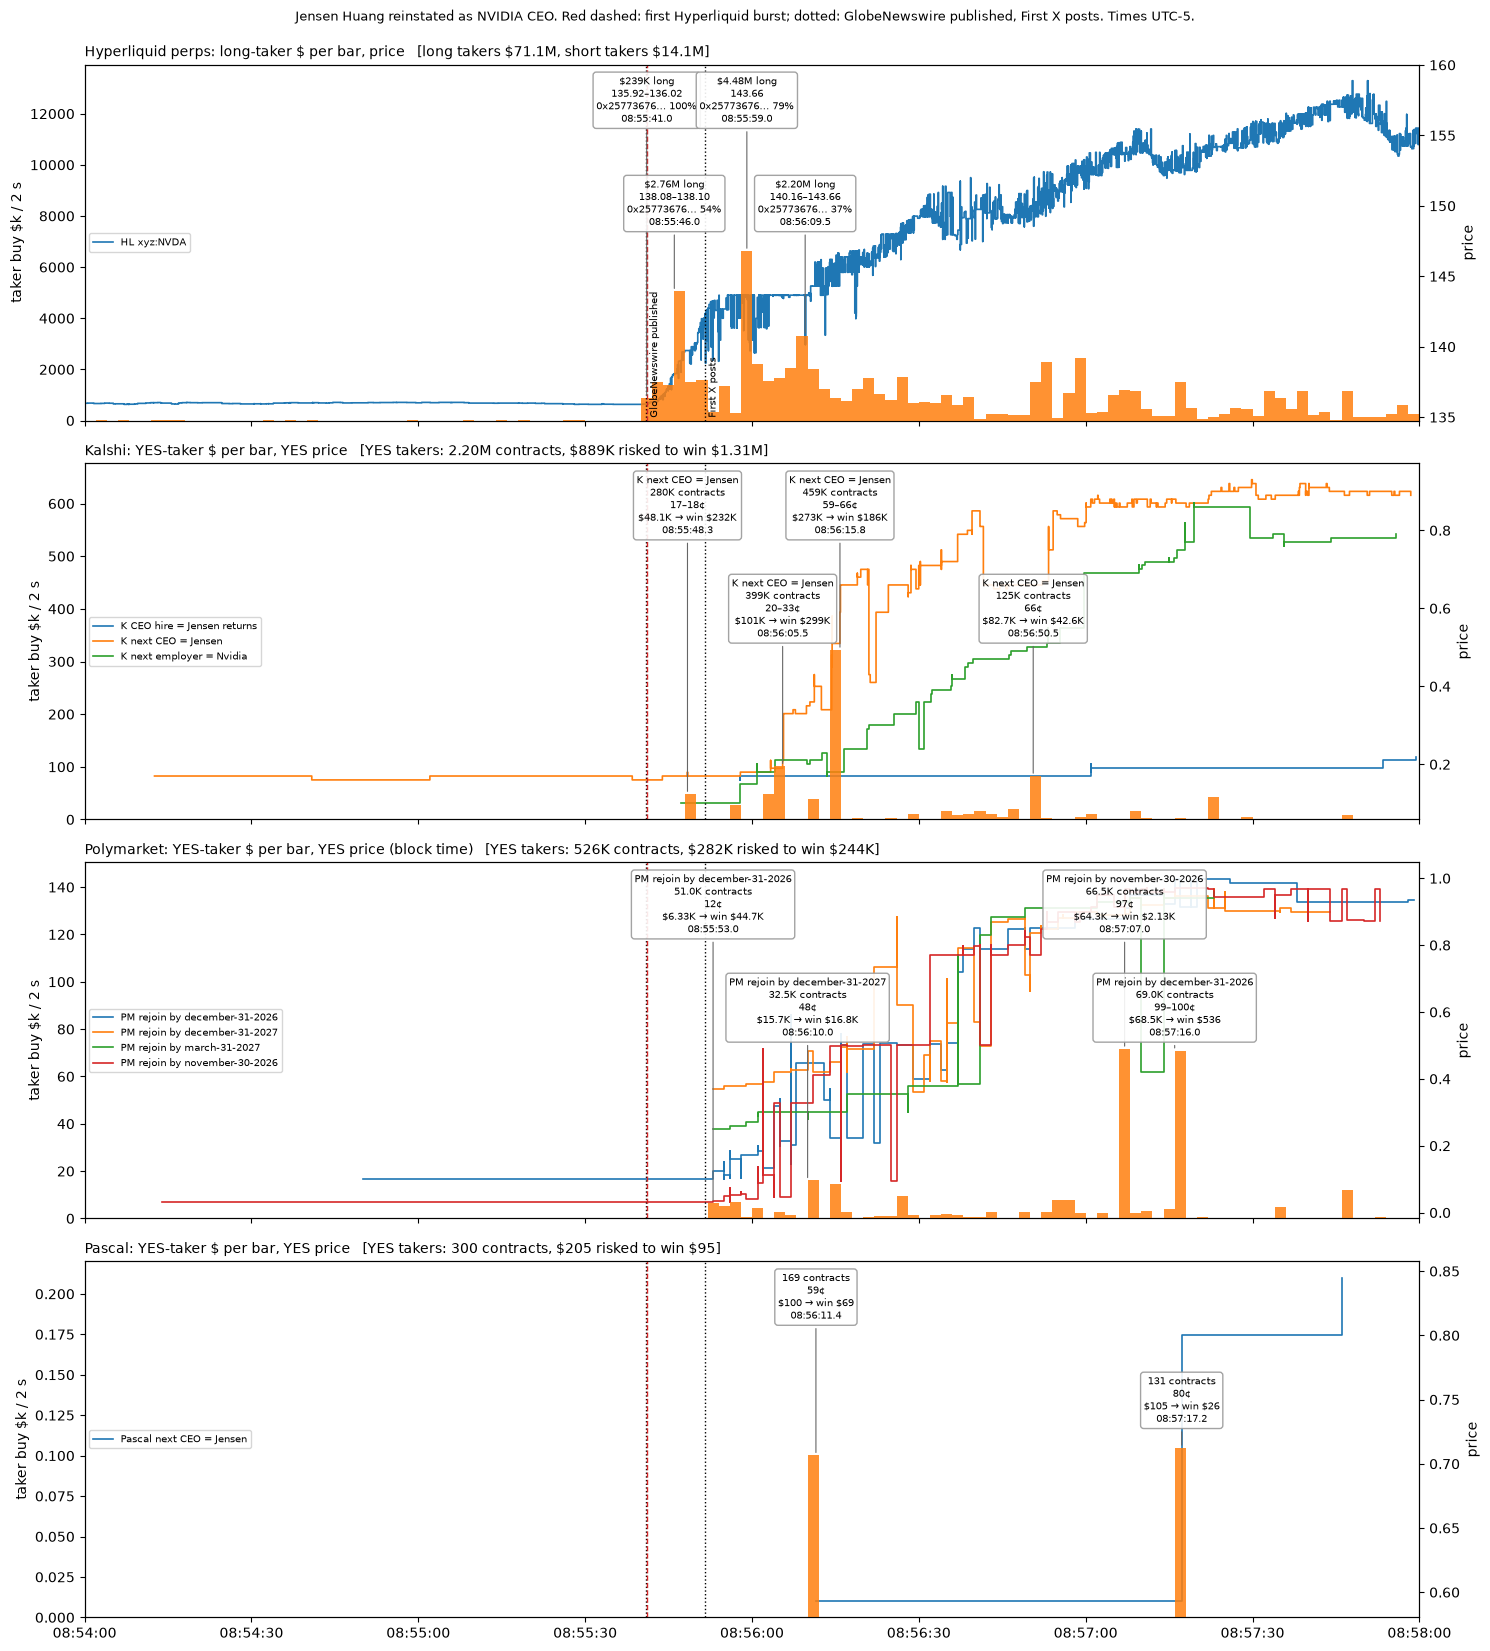

In [12]:
analysis.chart(tape, ev, ev.start_ms, ev.end_ms, 2000, annotate=4);

## 7b. Hyperliquid overlaid on the prediction markets
One clock, one plot. Top: YES prices (colored, left axis, ¢) with the HL perp's % move from its last pre-release trade (black, right axis). Bottom: each venue's YES/long taker buying, accumulated as a % of that venue's window total. Venues differ in size by 100×, so this compares *when* each one bought, not how much. Red dashed is GlobeNewswire's publish second (t=0).

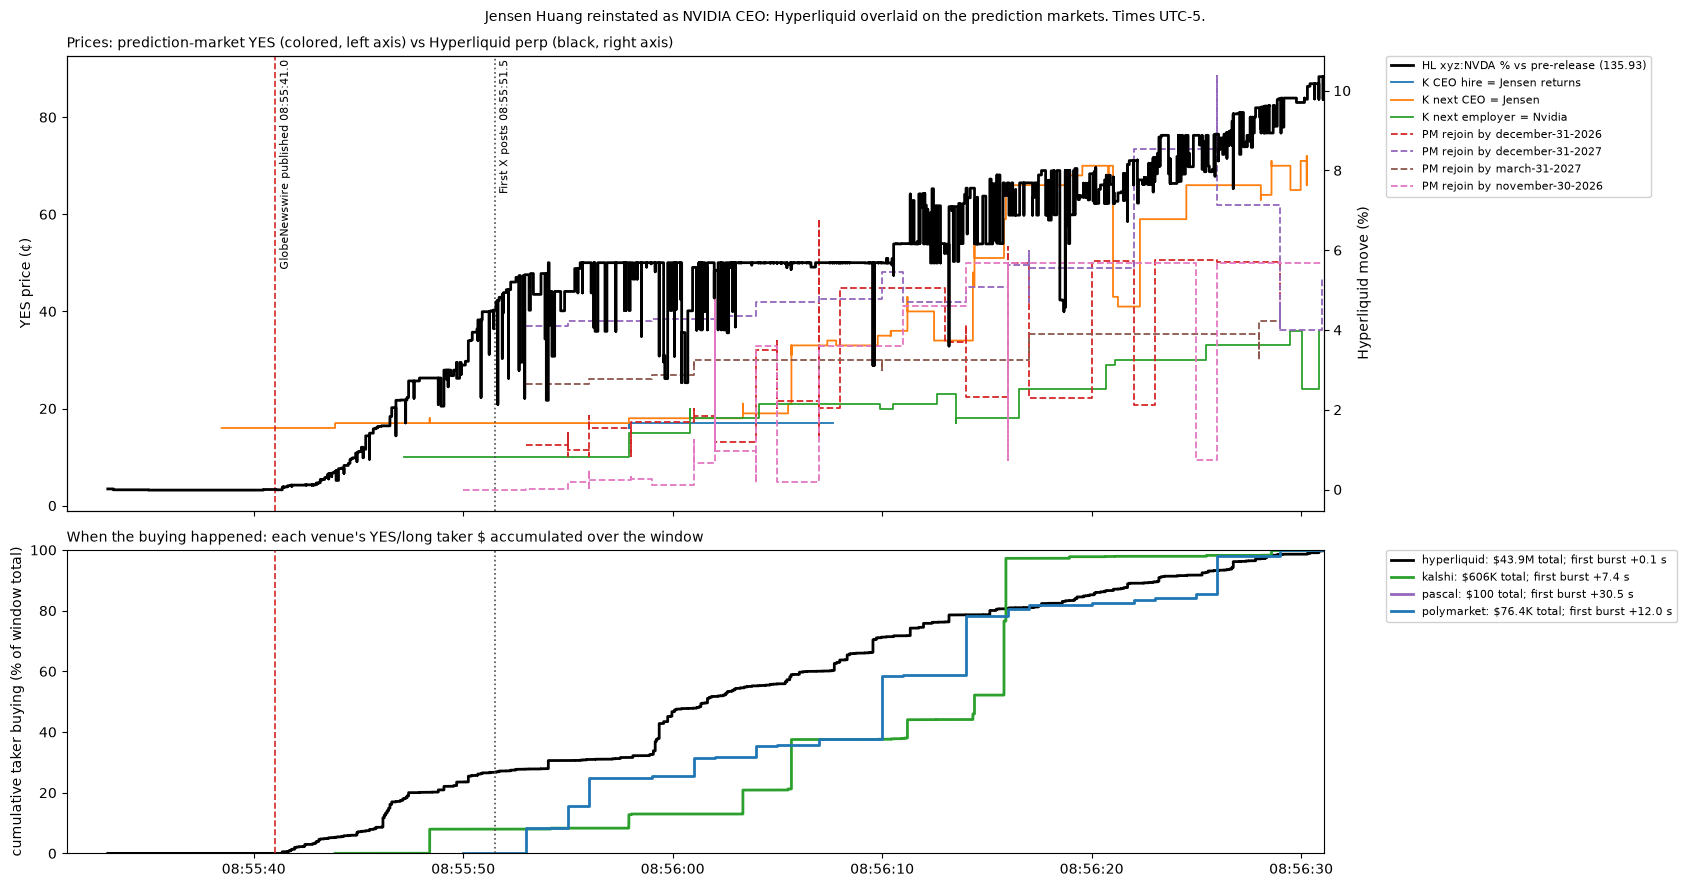

In [13]:
analysis.overlay(tape, ev, hl0 - 10_000, hl0 + 50_000);

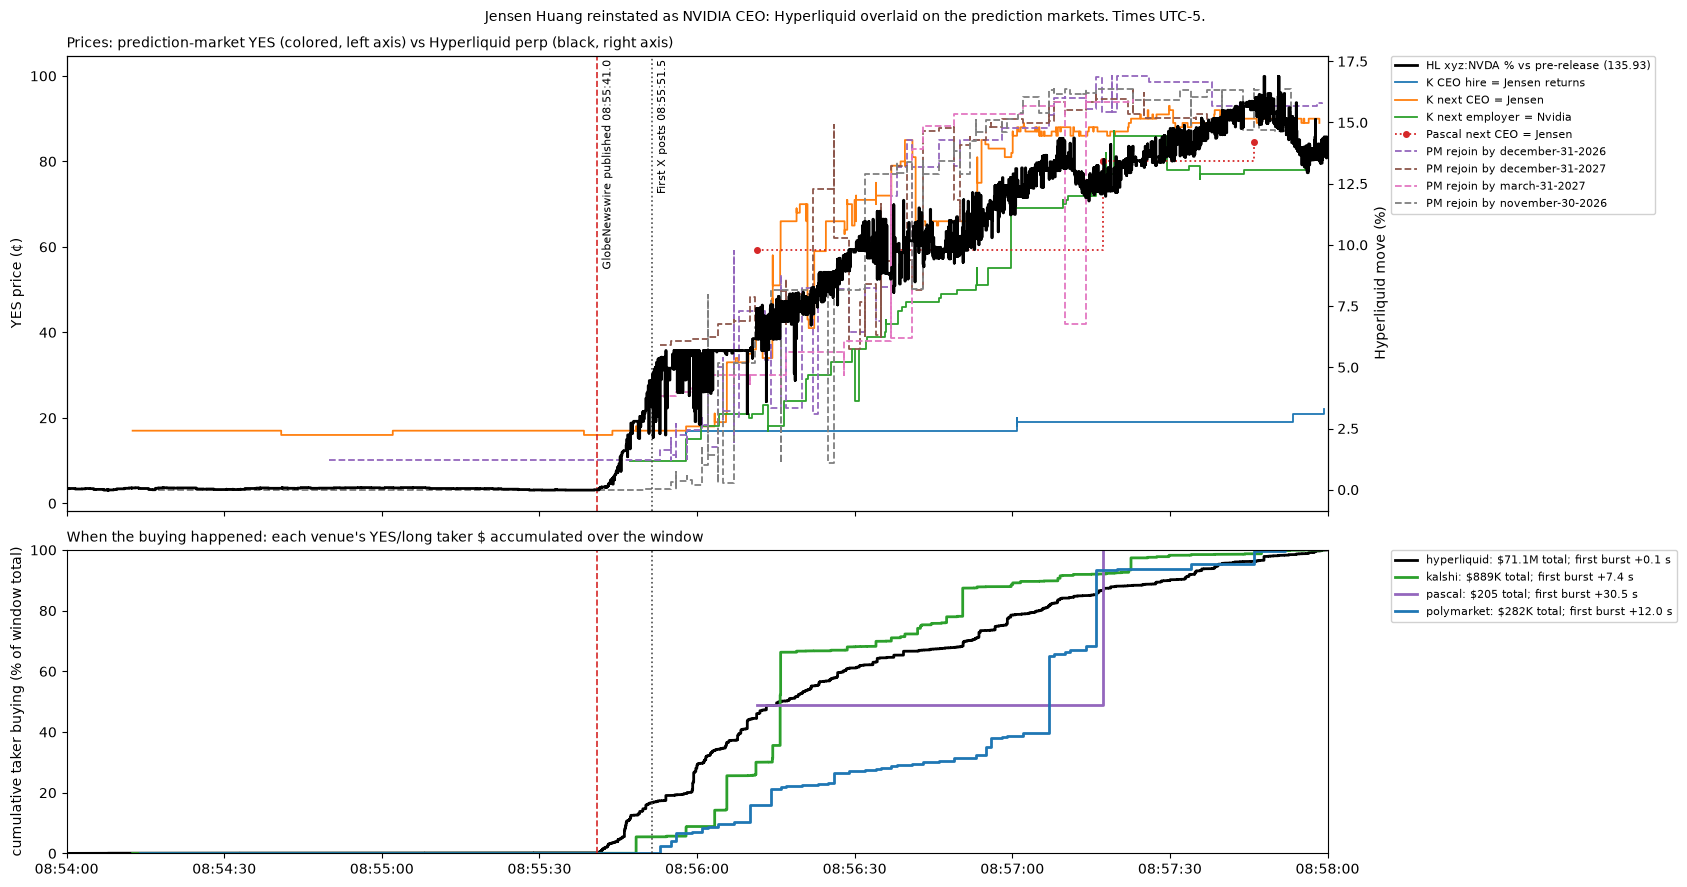

In [14]:
analysis.overlay(tape, ev, ev.start_ms, ev.end_ms);

- HL's black line leaves the floor in the same second as the release. Kalshi's and Polymarket's prices don't move until 8:55:48 and 8:55:53, by which point HL is already up 2.8% and 5.4%.
- In the first minute, HL front-loads its buying: 27% of its buying in this 60 s window is done before the first X post. Kalshi buys in a few large steps, the biggest at 8:56:15.8 (459K contracts). Polymarket climbs in small steps on thin books.
- Over the full window, prediction-market YES prices and the HL move track each other closely after 8:56:30; the divergence is all in the first 10–30 s.

## 8. Was Hyperliquid the trigger?
One event can't separate (a) prediction-market takers watching HL NVDA and reacting to it from (b) everyone reading the same wire, with HL's bots simply fastest. Both predict HL first.

What would separate them, across a set of past news events:
1. The gap between HL's first burst and Kalshi's or Polymarket's first burst. A tight, consistent gap supports (a).
2. HL bursts with no news (false signals). If prediction markets jump on those too, takers are trading HL itself.
3. News that prediction markets priced while HL didn't move. This shows how much of the flow needs HL at all.

Each new event is a new file in `events/` plus `make all EVENT=events/<name>.toml`. Ironflow's keyless tier reaches only 24 h back, so past events need Hyperliquid's S3 archive (AWS credentials).